## 04 – Modeling & Evaluation Prototype (Milestone 4 – Level 2, N05)
Chạy đúng Evaluation Plan đã chốt trước (`evaluation/evaluation_plan.json`, SHA-256 trong `.lock`). Input: prepared dataset P3 `N05-prepared-v1.0` (kiểm tra SHA-256).

In [1]:
import sys, json; sys.path.insert(0,'../src')
import pandas as pd
import run_prototype as rp
rp.main()

Input OK: plan 0b8e71483d6e frozen 2026-11-09T14:55:01Z; data N05-prepared-v1.2


AQ1 done: checks True True


AQ2 done: first week 1; significant 13/16


AQ3: primary M2 (gain -0.0066); test {'pr_auc': 0.6623, 'roc_auc': 0.7315, 'recall': 0.6933, 'precision': 0.5188, 'f1': 0.5935, 'brier': 0.1981, 'flagged_share': 0.5047}


AQ4: chosen a, val P@200 {'a': 0.8475, 'b': 0.665, 'd': 0.8575}, success True


AQ5: faithful err 8.88e-16; >=2 reasons 1.0
Fairness flags: {'gender': False, 'age_band': False, 'disability': False, 'imd_group': True}


PD-02 reduced LR: test 0.6573 vs primary 0.6623; sign inconsistent 0


Extras: PR-AUC CI [0.637, 0.686], recall CI [0.668, 0.717], cal test {'mean_pred': 0.4426, 'base_rate': 0.3776, 'slope': 0.97, 'intercept': -0.335}
done 10.1 s


### Evaluation Plan (đã chốt)

In [2]:
print(open('../evaluation/evaluation_plan.lock').read())
json.load(open('../evaluation/evaluation_plan.json'))['AQ3']

{"sha256": "0b8e71483d6e47219d04f8f61e3db8b0b0075c29a14e5da2b489219d8f57e8b7", "frozen_utc": "2026-11-09T14:55:01Z"}


{'task': 'binary classification, target_noncompletion, prediction point end of day 28',
 'split': 'fit on train (2013B, 2013J); select model and threshold on validation (2014B); evaluate test (2014J) once',
 'models': {'M0': 'majority / prevalence baseline',
  'M1': 'simple rule: not submitted TMA1 first, then fewer active days 0-28',
  'M2': 'logistic regression L2 (C=1.0), median impute + log1p counts + standardize, fit on train',
  'M3': 'histogram gradient boosting (max_iter=200, learning_rate=0.1, default depth), fit on train',
  'variants': 'core features (no tma1_score) = default; +tma1_score = sensitivity (DQ10)'},
 'feature_policy': 'no sensitive attributes, no final_result/date_unregistration, only features <= day 28',
 'primary_metric': 'PR-AUC on test',
 'secondary_metrics': ['ROC-AUC',
  'Recall, Precision, F1 at threshold t*',
  'Brier score',
  'calibration curve'],
 'threshold_rule': 't* = highest threshold with Recall >= 0.70 on validation',
 'selection_rule': 'primary

### AQ3 – so sánh mô hình (threshold chọn trên validation)

In [3]:
r=json.load(open('../results/aq3_results.json'))
pd.DataFrame({k:{**{'val_'+a:b for a,b in v['validation'].items()},**{'test_'+a:b for a,b in v['test'].items()}} for k,v in r['models'].items()}).T[['val_pr_auc','test_pr_auc','test_roc_auc','test_recall','test_precision','test_brier']]

,val_pr_auc,test_pr_auc,test_roc_auc,test_recall,test_precision,test_brier
M0,0.4649,0.3776,0.5000,0.0000,0.0000,0.2400
M1,0.6882,0.6148,0.6863,0.7144,0.4724,0.2042
M2,0.7363,0.6623,0.7315,0.6933,0.5188,0.1981
M3,0.7297,0.6445,0.7167,0.6642,0.5323,0.2081
M2+score,0.7494,0.5330,0.6842,0.6701,0.5171,0.2485
M3+score,0.7374,0.5817,0.6906,0.6708,0.5035,0.2410


In [4]:
r['selection']

{'validation_gain_M3_over_M2': -0.0066,
 'primary': 'M2',
 'validation_gain_with_score': -0.012,
 'success_AQ3': False}

### AQ2 – effect size

In [5]:
pd.DataFrame(json.load(open('../results/aq2_results.json'))['unadjusted'])

,indicator,type,median_noncompl,median_compl,effect,effect_name,p,n1,n0,p_holm,significant
0,clicks_w1,continuous,24.000000,59.000000,-0.260,Cliff's delta,0.000000,5621,7399,0.000000,True
1,clicks_w2,continuous,18.000000,50.000000,-0.297,Cliff's delta,0.000000,5621,7399,0.000000,True
2,clicks_w3,continuous,27.000000,60.000000,-0.261,Cliff's delta,0.000000,5621,7399,0.000000,True
3,clicks_w4,continuous,13.000000,43.000000,-0.290,Cliff's delta,0.000000,5621,7399,0.000000,True
4,active_days_w1,continuous,2.000000,3.000000,-0.263,Cliff's delta,0.000000,5621,7399,0.000000,True
5,active_days_w2,continuous,1.000000,3.000000,-0.307,Cliff's delta,0.000000,5621,7399,0.000000,True
6,active_days_w3,continuous,2.000000,3.000000,-0.296,Cliff's delta,0.000000,5621,7399,0.000000,True
7,active_days_w4,continuous,2.000000,3.000000,-0.313,Cliff's delta,0.000000,5621,7399,0.000000,True
8,clicks_change_w1_w4,continuous,-0.031749,-0.149532,-0.041,Cliff's delta,0.000063,5621,7399,0.000063,False
9,days_since_last_active_d28,continuous,3.000000,1.000000,0.303,Cliff's delta,0.000000,5621,7399,0.000000,True


### AQ4 – Precision@k

In [6]:
a=json.load(open('../results/aq4_results.json')); a['selection'], a['smart_scenario_test']

({'validation_precision_at_200': {'a': 0.8475, 'b': 0.665, 'd': 0.8575},
  'chosen_by_frozen_rule': 'd',
  'feasible_under_capacity_200_per_module': {'a': True, 'b': True, 'd': False},
  'chosen_rule': 'a',
  'plan_deviation': 'PD-01: loại quy tắc vi phạm trần 200 ca/module-kỳ (C05) trước khi chọn',
  'success_AQ4': True},
 {'BBB-2014J': {'baseline_rate': 0.3555,
   'after_rate_if_14pct': 0.3436,
   'drop_pp': 1.19},
  'FFF-2014J': {'baseline_rate': 0.3988,
   'after_rate_if_14pct': 0.3856,
   'drop_pp': 1.33}})

### AQ5 – ví dụ lời giải thích

In [7]:
json.load(open('../results/aq5_results.json'))['examples']

[{'student': 'BBB-2014J-2698591',
  'p': 0.957,
  'actual': 1,
  'reasons': [{'feature': 'tma1_submitted_by_d28',
    'contribution_logit': 1.142},
   {'feature': 'active_days_0_28', 'contribution_logit': 0.673},
   {'feature': 'clicks_homepage_0_28', 'contribution_logit': 0.532}],
  'text': 'Chưa nộp bài đánh giá đầu tiên (TMA1) tính đến ngày 28. Số ngày có hoạt động trên vle trong 4 tuần đầu thấp hơn mức thường gặp (0 so với trung vị 11). Lượt tương tác với tài nguyên homepage thấp hơn mức thường gặp (0 so với trung vị 40).'},
 {'student': 'BBB-2014J-689298',
  'p': 0.947,
  'actual': 1,
  'reasons': [{'feature': 'tma1_submitted_by_d28',
    'contribution_logit': 1.142},
   {'feature': 'active_days_0_28', 'contribution_logit': 0.616},
   {'feature': 'clicks_w2', 'contribution_logit': 0.298}],
  'text': 'Chưa nộp bài đánh giá đầu tiên (TMA1) tính đến ngày 28. Số ngày có hoạt động trên vle trong 4 tuần đầu thấp hơn mức thường gặp (1 so với trung vị 11). Lượt tương tác tuần 2 thấp hơn m

### Fairness & error analysis

In [8]:
f=json.load(open('../results/fairness_error_results.json'))
{k:(v['recall_gap'],v['flag']) for k,v in f['fairness'].items()}

{'gender': (0.022, False),
 'age_band': (0.014, False),
 'disability': (0.002, False),
 'imd_group': (0.166, True)}

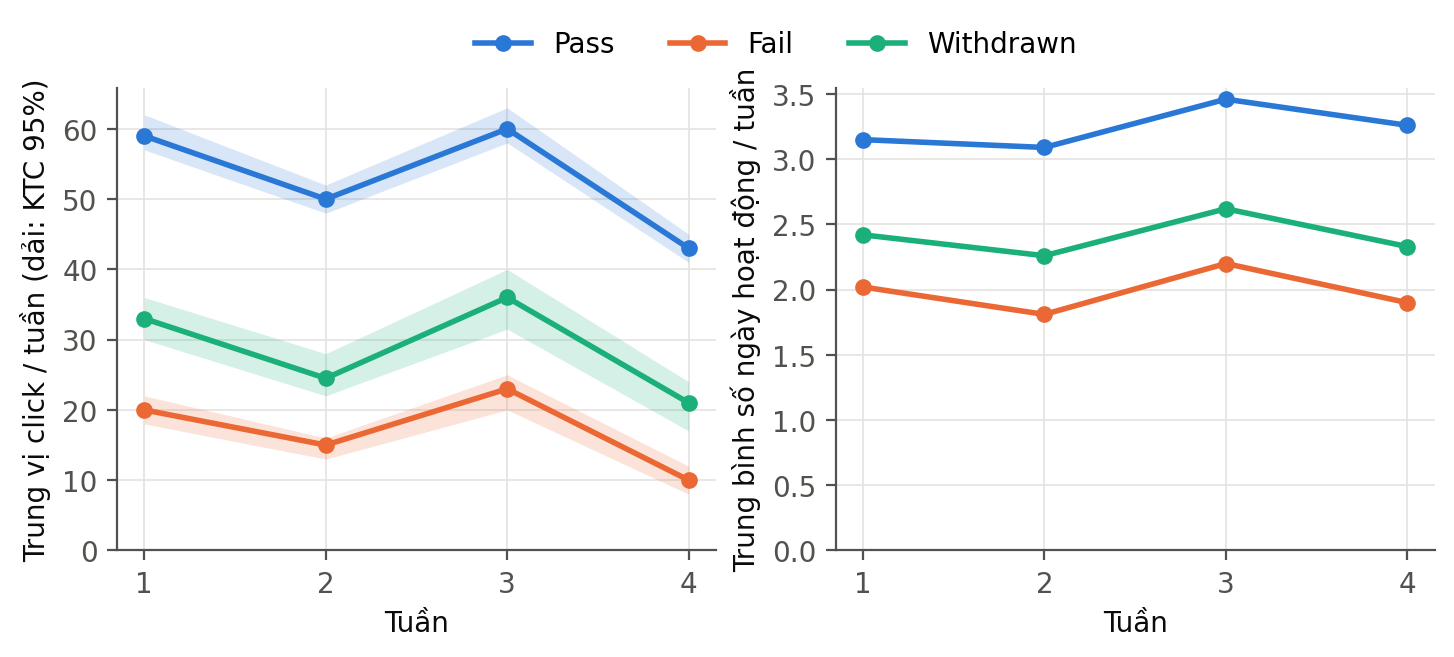

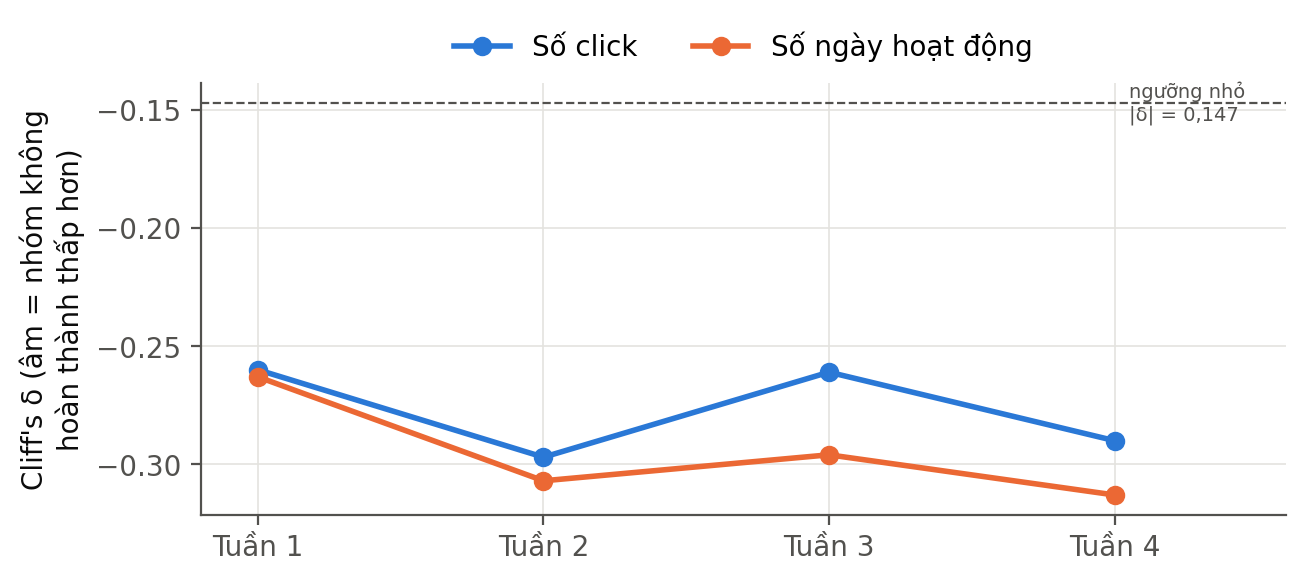

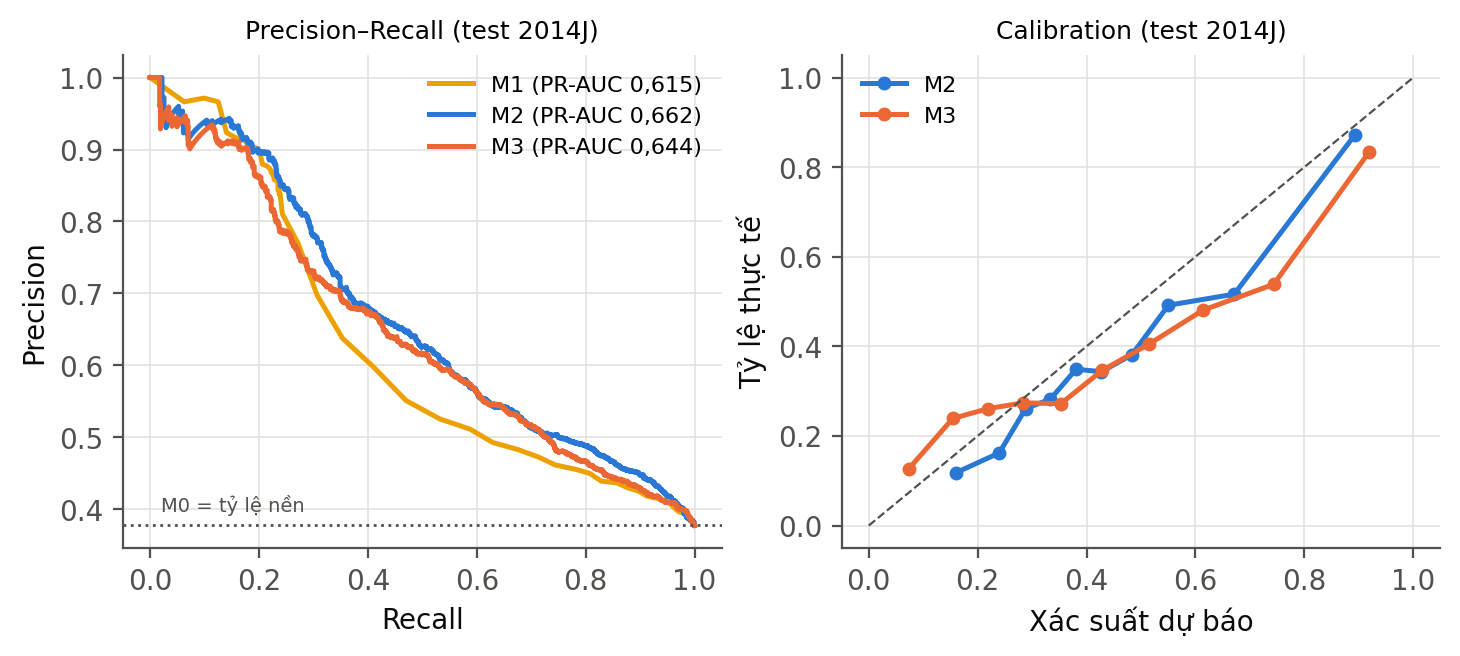

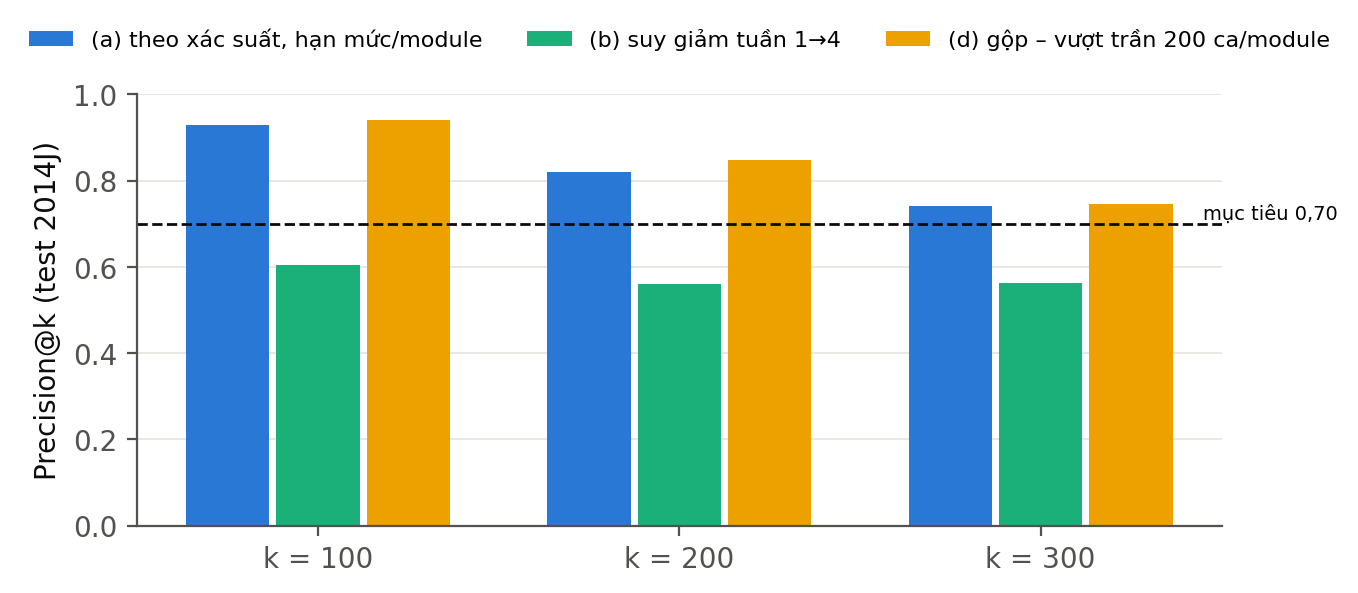

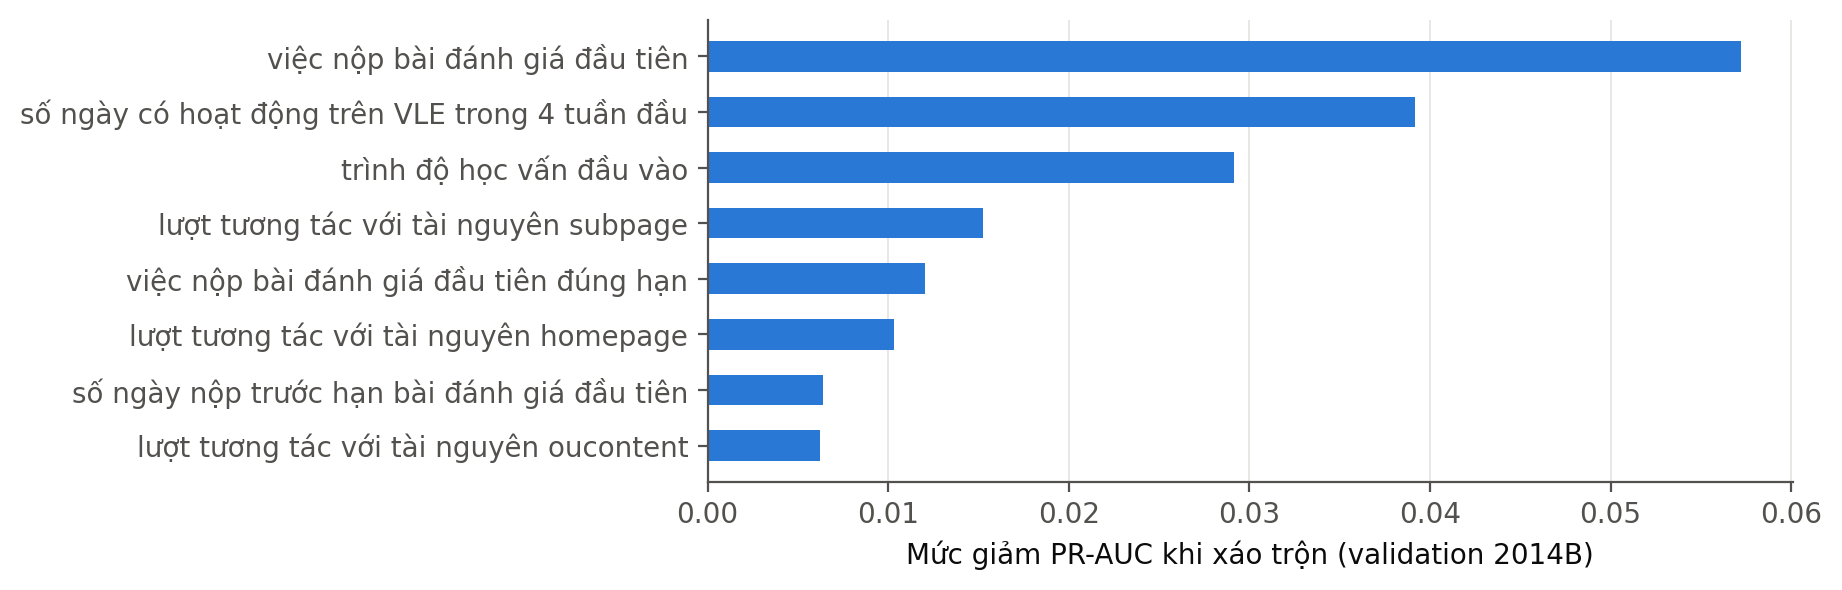

In [9]:
from IPython.display import Image, display
from pathlib import Path
for p in sorted(Path('../reports/milestone4/figures').glob('*.png')): display(Image(str(p), width=650))